# Predicting the Price of a Football Player

This notebook consolidates Tasks 1–6: exploratory data analysis, regression models, hyperparameter tuning, model selection, Genetic Algorithm feature weighting for KNN, and a Flask REST API.

**Dataset path:** `/Users/vishalsingh/Desktop/SABUDH - 26/ML/Assignment 06 – Predicting the price of a Football player/Data set__1682565729-62fcaa4ea2bc0b6439d2306a.csv`

Place the CSV in the same folder as this notebook before running all cells.

## 0. Setup

In [1]:
# If required, install the libraries by uncommenting this line:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib flask

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

import joblib

RANDOM_STATE = 42
DATA_PATH = "/Users/vishalsingh/Desktop/SABUDH - 26/ML/Assignment 06 – Predicting the price of a Football player/Data set__1682565729-62fcaa4ea2bc0b6439d2306a.csv"
OUTPUT_DIR = os.getcwd()

sns.set_theme(style="whitegrid")

## 1. Load and prepare the dataset

In [2]:
data = pd.read_csv(DATA_PATH)

# Convert FPL selection percentage from text (for example, '17.10%') to numeric.
data["fpl_sel"] = (
    data["fpl_sel"].astype(str).str.replace("%", "", regex=False).astype(float)
)

print("Dataset shape:", data.shape)
display(data.head())
display(data.info())

Dataset shape: (461, 17)


,name,club,age,position,position_cat,market_value,page_views,fpl_value,fpl_sel,fpl_points,region,nationality,new_foreign,age_cat,club_id,big_club,new_signing
0,Alexis Sanchez,Arsenal,28,LW,1,65.0,4329,12.0,17.1,264,3.0,Chile,0,4,1,1,0
1,Mesut Ozil,Arsenal,28,AM,1,50.0,4395,9.5,5.6,167,2.0,Germany,0,4,1,1,0
2,Petr Cech,Arsenal,35,GK,4,7.0,1529,5.5,5.9,134,2.0,Czech Republic,0,6,1,1,0
3,Theo Walcott,Arsenal,28,RW,1,20.0,2393,7.5,1.5,122,1.0,England,0,4,1,1,0
4,Laurent Koscielny,Arsenal,31,CB,3,22.0,912,6.0,0.7,121,2.0,France,0,4,1,1,0


<class 'pandas.DataFrame'>
RangeIndex: 461 entries, 0 to 460
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          461 non-null    str    
 1   club          461 non-null    str    
 2   age           461 non-null    int64  
 3   position      461 non-null    str    
 4   position_cat  461 non-null    int64  
 5   market_value  461 non-null    float64
 6   page_views    461 non-null    int64  
 7   fpl_value     461 non-null    float64
 8   fpl_sel       461 non-null    float64
 9   fpl_points    461 non-null    int64  
 10  region        460 non-null    float64
 11  nationality   461 non-null    str    
 12  new_foreign   461 non-null    int64  
 13  age_cat       461 non-null    int64  
 14  club_id       461 non-null    int64  
 15  big_club      461 non-null    int64  
 16  new_signing   461 non-null    int64  
dtypes: float64(4), int64(9), str(4)
memory usage: 61.4 KB


None

In [3]:
print("Missing values:")
display(data.isnull().sum())

print("Duplicate rows:", data.duplicated().sum())

target = "market_value"
features = [
    "age", "position", "club", "page_views", "fpl_value",
    "fpl_sel", "fpl_points", "region", "new_foreign",
    "big_club", "new_signing"
]

X = data[features].copy()
y = data[target].copy()

numerical_columns = [
    "age", "page_views", "fpl_value", "fpl_sel", "fpl_points",
    "region", "new_foreign", "big_club", "new_signing"
]
categorical_columns = ["position", "club"]

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Missing values:


name            0
club            0
age             0
position        0
position_cat    0
market_value    0
page_views      0
fpl_value       0
fpl_sel         0
fpl_points      0
region          1
nationality     0
new_foreign     0
age_cat         0
club_id         0
big_club        0
new_signing     0
dtype: int64

Duplicate rows: 0
Training records: 368
Testing records: 93


## Task 1 – Exploratory Data Analysis

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,461,461,Alexis Sanchez,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
club,461,20,Arsenal,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,461.0,NaN,NaN,NaN,26.804772,3.961892,17.0,24.0,27.0,30.0,38.0
position,461,13,CB,85,NaN,NaN,NaN,NaN,NaN,NaN,NaN
position_cat,461.0,NaN,NaN,NaN,2.180043,1.000061,1.0,1.0,2.0,3.0,4.0
market_value,461.0,NaN,NaN,NaN,11.012039,12.257403,0.05,3.0,7.0,15.0,75.0
page_views,461.0,NaN,NaN,NaN,763.776573,931.805757,3.0,220.0,460.0,896.0,7664.0
fpl_value,461.0,NaN,NaN,NaN,5.447939,1.346695,4.0,4.5,5.0,5.5,12.5
fpl_sel,461.0,NaN,NaN,NaN,3.244252,5.675657,0.0,0.2,1.0,3.3,45.0
fpl_points,461.0,NaN,NaN,NaN,57.314534,53.113811,0.0,5.0,51.0,94.0,264.0


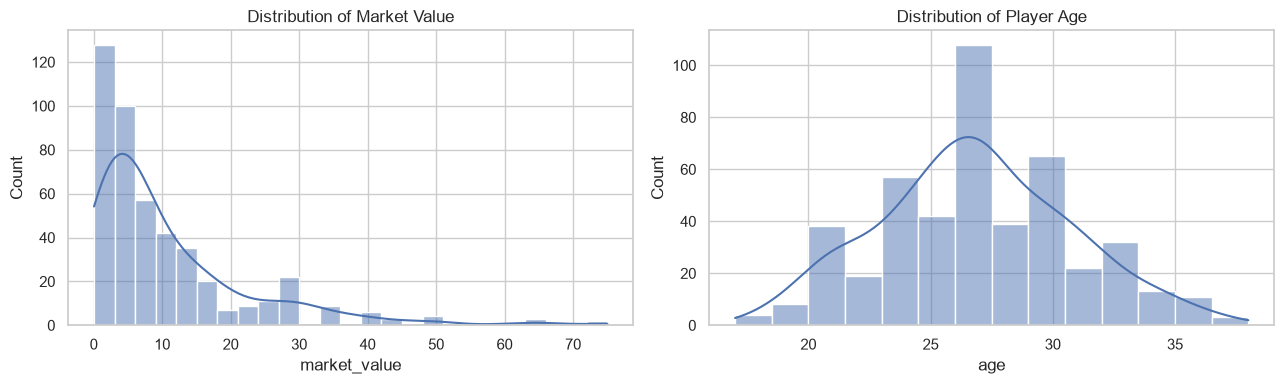

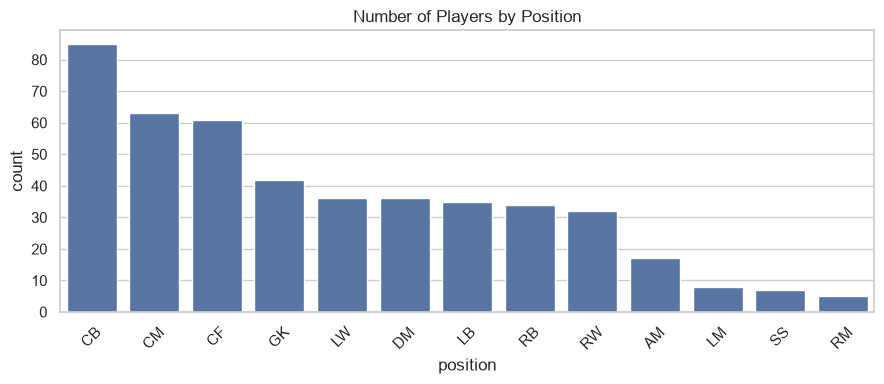

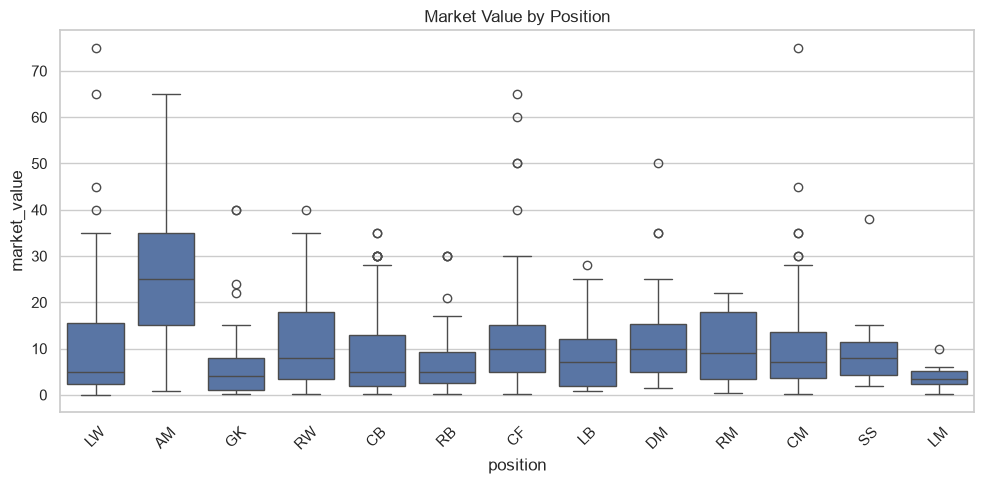

In [4]:
display(data.describe(include="all").T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data["market_value"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of Market Value")
sns.histplot(data["age"], kde=True, ax=axes[1])
axes[1].set_title("Distribution of Player Age")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.countplot(data=data, x="position", order=data["position"].value_counts().index)
plt.title("Number of Players by Position")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x="position", y="market_value")
plt.title("Market Value by Position")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

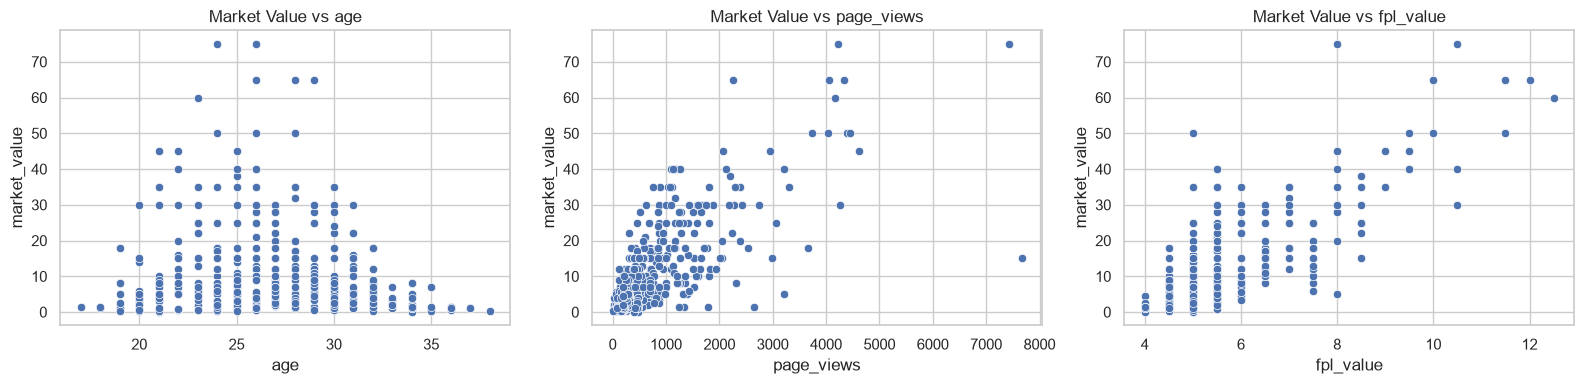

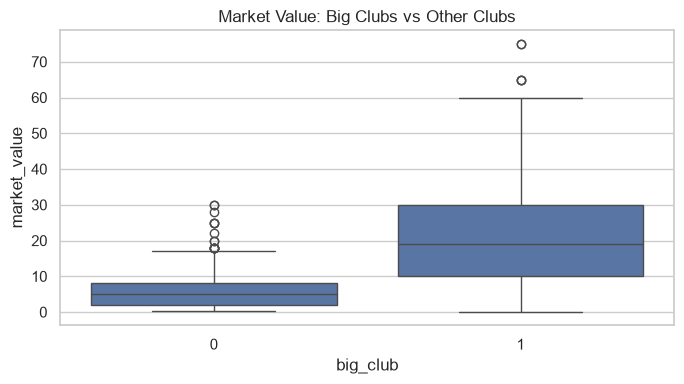

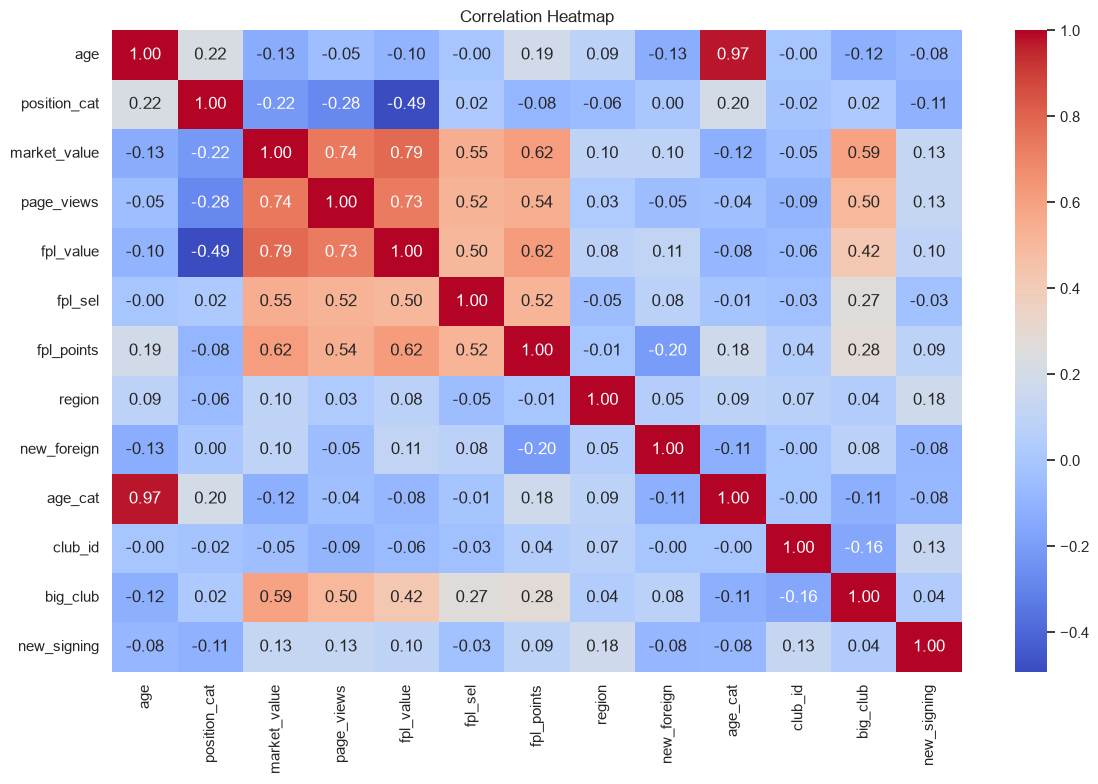

Average market value: 11.01
Minimum market value: 0.05
Maximum market value: 75.0
Average player age: 26.8

Correlation with market value:


market_value    1.000000
fpl_value       0.788653
page_views      0.739657
fpl_points      0.615155
big_club        0.593483
fpl_sel         0.548703
new_signing     0.131321
region          0.101659
new_foreign     0.098056
club_id        -0.046068
age_cat        -0.117682
age            -0.132396
position_cat   -0.217637
Name: market_value, dtype: float64


Average market value by position:


position
AM    26.161765
CF    13.823770
LW    13.293056
DM    12.347222
RW    12.195312
SS    11.357143
CM    10.960317
RM    10.600000
CB     8.972353
LB     8.300000
RB     7.742647
GK     7.234524
LM     4.000000
Name: market_value, dtype: float64

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["age", "page_views", "fpl_value"]):
    sns.scatterplot(data=data, x=col, y="market_value", ax=ax)
    ax.set_title(f"Market Value vs {col}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=data, x="big_club", y="market_value")
plt.title("Market Value: Big Clubs vs Other Clubs")
plt.tight_layout()
plt.show()

numeric_data = data.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Average market value:", round(data["market_value"].mean(), 2))
print("Minimum market value:", round(data["market_value"].min(), 2))
print("Maximum market value:", round(data["market_value"].max(), 2))
print("Average player age:", round(data["age"].mean(), 2))
print("\nCorrelation with market value:")
display(numeric_data.corr()["market_value"].sort_values(ascending=False))

print("\nAverage market value by position:")
display(data.groupby("position")["market_value"].mean().sort_values(ascending=False))

## Task 2 – Build and compare eight regression models

In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(alpha=1),
    "Ridge": Ridge(alpha=1),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}

task2_results = []
task2_pipelines = {}

for name, model in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)

    task2_pipelines[name] = pipe
    task2_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

task2_results_df = pd.DataFrame(task2_results).sort_values("RMSE")
display(task2_results_df)
task2_results_df.to_csv(os.path.join(OUTPUT_DIR, "Task_2_Model_Results.csv"), index=False)

,Model,MAE,MSE,RMSE,R2
6,Random Forest,2.898398,17.521543,4.185874,0.855256
7,Gradient Boosting,3.152087,21.449878,4.631401,0.822804
2,Ridge,3.558353,21.712643,4.659683,0.820633
1,Lasso,3.556877,22.068416,4.697703,0.817694
0,Linear Regression,3.601467,22.213521,4.713122,0.816496
3,KNN,3.424624,22.359678,4.728602,0.815288
5,Decision Tree,4.201613,41.776210,6.463452,0.654889
4,SVR,4.517734,69.220877,8.319908,0.428171


## Task 3 – Hyperparameter tuning with GridSearchCV

In [7]:
param_grids = {
    "Lasso": {
        "model__alpha": [0.01, 0.1, 1, 10, 100]
    },
    "Ridge": {
        "model__alpha": [0.01, 0.1, 1, 10, 100]
    },
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"]
    },
    "SVR": {
        "model__C": [1, 10, 50, 100],
        "model__epsilon": [0.1, 0.2, 0.5],
        "model__kernel": ["linear", "rbf"]
    },
    "Decision Tree": {
        "model__max_depth": [None, 5, 10, 15],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },
    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2]
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__max_depth": [2, 3, 4]
    }
}

tuning_models = {
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(),
    "SVR": SVR(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}

tuned_results = []
best_estimators = {}

for name, estimator in tuning_models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    search = GridSearchCV(
        pipeline,
        param_grids[name],
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    best_estimators[name] = search.best_estimator_

    pred = search.best_estimator_.predict(X_test)
    tuned_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "Best CV RMSE": -search.best_score_,
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test R2": r2_score(y_test, pred)
    })

tuned_results_df = pd.DataFrame(tuned_results).sort_values("Best CV RMSE")
display(tuned_results_df)
tuned_results_df.to_csv(os.path.join(OUTPUT_DIR, "Task_3_Tuned_Results.csv"), index=False)

task3_best_name = tuned_results_df.iloc[0]["Model"]
task3_best_model = best_estimators[task3_best_name]
joblib.dump(task3_best_model, os.path.join(OUTPUT_DIR, "Task_3_Best_Model.pkl"))

print("Best model by GridSearchCV:", task3_best_name)

,Model,Best Parameters,Best CV RMSE,Test MAE,Test RMSE,Test R2
6,Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",5.519227,3.285492,4.910280,0.800822
3,SVR,"{'model__C': 100, 'model__epsilon': 0.5, 'mode...",5.735614,3.093323,4.542896,0.829512
5,Random Forest,"{'model__max_depth': None, 'model__min_samples...",6.115496,2.914344,4.196711,0.854505
1,Ridge,{'model__alpha': 10},6.137520,3.460330,4.522653,0.831028
0,Lasso,{'model__alpha': 0.1},6.272786,3.579312,4.611532,0.824321
2,KNN,"{'model__n_neighbors': 7, 'model__weights': 'd...",6.575346,3.353604,4.590673,0.825907
4,Decision Tree,"{'model__max_depth': 15, 'model__min_samples_l...",7.941421,4.302734,6.085418,0.694078


Best model by GridSearchCV: Gradient Boosting


## Task 4 – Model selection using 5-fold cross-validation

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
selection_results = []
selection_pipelines = {}

for name, estimator in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    scores = cross_val_score(
        pipeline, X_train, y_train,
        cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    mean_rmse = -scores.mean()
    selection_results.append({
        "Model": name,
        "Average CV RMSE": mean_rmse,
        "CV RMSE Std": scores.std()
    })
    selection_pipelines[name] = pipeline

selection_df = pd.DataFrame(selection_results).sort_values("Average CV RMSE")
display(selection_df)
selection_df.to_csv(os.path.join(OUTPUT_DIR, "Task_4_Model_Selection.csv"), index=False)

best_model_name = selection_df.iloc[0]["Model"]
best_model = selection_pipelines[best_model_name]
best_model.fit(X_train, y_train)

best_predictions = best_model.predict(X_test)
print("Selected model:", best_model_name)
print("Test MAE:", mean_absolute_error(y_test, best_predictions))
print("Test MSE:", mean_squared_error(y_test, best_predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, best_predictions)))
print("Test R2:", r2_score(y_test, best_predictions))

joblib.dump(best_model, os.path.join(OUTPUT_DIR, "Task_4_Best_Model.pkl"))
print("Saved Task_4_Best_Model.pkl")

,Model,Average CV RMSE,CV RMSE Std
7,Gradient Boosting,5.871852,1.121746
6,Random Forest,6.107885,1.175002
3,KNN,6.626931,1.234603
2,Ridge,6.664388,1.113454
0,Linear Regression,6.719137,1.065523
1,Lasso,7.114279,1.493215
5,Decision Tree,8.242324,1.244250
4,SVR,9.392997,2.279478


Selected model: Gradient Boosting
Test MAE: 3.152086726106978
Test MSE: 21.44987801870017
Test RMSE: 4.631401301841611
Test R2: 0.8228039659135092
Saved Task_4_Best_Model.pkl


## Task 5 – Genetic Algorithm for KNN feature weighting

In [9]:
# This task implements the assignment's weighted KNN approach on the original
# 11 input features. Numeric and categorical distances are handled separately.

ga_features = features.copy()
ga_numeric = [
    "age", "page_views", "fpl_value", "fpl_sel", "fpl_points",
    "region", "new_foreign", "big_club", "new_signing"
]
ga_categorical = ["position", "club"]

X_ga_train, X_ga_test, y_ga_train, y_ga_test = train_test_split(
    data[ga_features].copy(), y, test_size=0.2, random_state=RANDOM_STATE
)
X_ga_fit, X_ga_val, y_ga_fit, y_ga_val = train_test_split(
    X_ga_train, y_ga_train, test_size=0.2, random_state=RANDOM_STATE
)

def build_distance_matrix(reference_data, query_data):
    distances = np.zeros((len(query_data), len(reference_data), len(ga_features)))

    for j, col in enumerate(ga_features):
        ref = reference_data[col].copy()
        query = query_data[col].copy()

        if col in ga_numeric:
            median = ref.median()
            ref = ref.fillna(median).astype(float)
            query = query.fillna(median).astype(float)
            minimum, maximum = ref.min(), ref.max()
            scale = maximum - minimum
            if scale == 0:
                distances[:, :, j] = 0
            else:
                ref_scaled = (ref.to_numpy() - minimum) / scale
                query_scaled = (query.to_numpy() - minimum) / scale
                distances[:, :, j] = np.abs(
                    query_scaled[:, None] - ref_scaled[None, :]
                )
        else:
            mode_values = ref.mode()
            fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
            ref = ref.fillna(fill_value).astype(str).to_numpy()
            query = query.fillna(fill_value).astype(str).to_numpy()
            distances[:, :, j] = (query[:, None] != ref[None, :]).astype(float)

    return distances

def weighted_knn_predict(distance_matrix, weights, target_values, k=5):
    weighted_distances = np.sum(distance_matrix * weights, axis=2) / (
        np.sum(weights) + 1e-12
    )
    predictions = []
    for row in weighted_distances:
        nearest_indices = np.argpartition(row, k - 1)[:k]
        predictions.append(np.mean(target_values.iloc[nearest_indices]))
    return np.array(predictions)

fit_distances = build_distance_matrix(X_ga_fit, X_ga_fit)
val_distances = build_distance_matrix(X_ga_fit, X_ga_val)
test_distances = build_distance_matrix(X_ga_train, X_ga_test)

y_ga_fit = y_ga_fit.reset_index(drop=True)
y_ga_val = y_ga_val.reset_index(drop=True)
y_ga_train = y_ga_train.reset_index(drop=True)
y_ga_test = y_ga_test.reset_index(drop=True)

def fitness(weights):
    predictions = weighted_knn_predict(val_distances, weights, y_ga_fit, k=5)
    return np.sqrt(mean_squared_error(y_ga_val, predictions))

np.random.seed(RANDOM_STATE)
population_size = 30
generations = 40
number_of_features = len(ga_features)
population = np.random.uniform(0, 1, (population_size, number_of_features))

best_weights = None
best_fitness = float("inf")
fitness_history = []

def tournament_selection(pop, scores, tournament_size=3):
    candidates = np.random.choice(len(pop), tournament_size, replace=False)
    winner = candidates[np.argmin(scores[candidates])]
    return pop[winner].copy()

for generation in range(generations):
    scores = np.array([fitness(individual) for individual in population])

    generation_best = np.argmin(scores)
    if scores[generation_best] < best_fitness:
        best_fitness = scores[generation_best]
        best_weights = population[generation_best].copy()

    fitness_history.append(best_fitness)

    # Keep the two best individuals (elitism).
    elite_indices = np.argsort(scores)[:2]
    new_population = [population[i].copy() for i in elite_indices]

    # Generate offspring through tournament selection, crossover and mutation.
    while len(new_population) < population_size - 4:
        parent1 = tournament_selection(population, scores)
        parent2 = tournament_selection(population, scores)

        mask = np.random.rand(number_of_features) < 0.5
        child = np.where(mask, parent1, parent2)

        if np.random.rand() < 0.3:
            gene = np.random.randint(number_of_features)
            child[gene] += np.random.normal(0, 0.15)
        child = np.clip(child, 0, 1)
        new_population.append(child)

    # Diversity mechanism: introduce four random immigrants each generation.
    for _ in range(4):
        new_population.append(np.random.uniform(0, 1, number_of_features))

    population = np.array(new_population)

print("Best validation RMSE:", round(best_fitness, 4))

Best validation RMSE: 4.5147


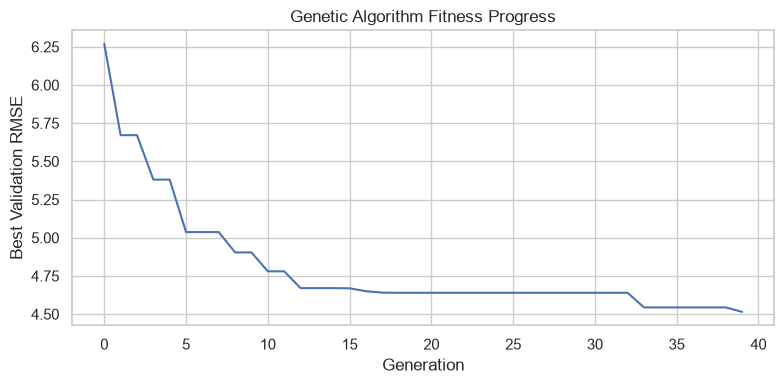

,Feature,Weight
9,big_club,1.000000
4,fpl_value,0.823161
5,fpl_sel,0.568959
3,page_views,0.532150
0,age,0.292145
1,position,0.087650
6,fpl_points,0.063558
7,region,0.046450
8,new_foreign,0.022385
2,club,0.000000


,Model,MAE,RMSE,R2
0,Normal KNN,3.925484,5.578773,0.742897
1,GA Weighted KNN,3.422258,4.754874,0.813230


In [10]:
plt.figure(figsize=(8, 4))
plt.plot(fitness_history)
plt.xlabel("Generation")
plt.ylabel("Best Validation RMSE")
plt.title("Genetic Algorithm Fitness Progress")
plt.tight_layout()
plt.show()

weights_df = pd.DataFrame({
    "Feature": ga_features,
    "Weight": best_weights
}).sort_values("Weight", ascending=False)
display(weights_df)
weights_df.to_csv(os.path.join(OUTPUT_DIR, "Task_5_Attribute_Weights.csv"), index=False)

# Compare standard KNN with GA-weighted KNN using the held-out test set.
normal_weights = np.ones(number_of_features)
normal_predictions = weighted_knn_predict(
    test_distances, normal_weights, y_ga_train, k=5
)
ga_predictions = weighted_knn_predict(
    test_distances, best_weights, y_ga_train, k=5
)

comparison_df = pd.DataFrame([
    {
        "Model": "Normal KNN",
        "MAE": mean_absolute_error(y_ga_test, normal_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_ga_test, normal_predictions)),
        "R2": r2_score(y_ga_test, normal_predictions)
    },
    {
        "Model": "GA Weighted KNN",
        "MAE": mean_absolute_error(y_ga_test, ga_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_ga_test, ga_predictions)),
        "R2": r2_score(y_ga_test, ga_predictions)
    }
])
display(comparison_df)
comparison_df.to_csv(os.path.join(OUTPUT_DIR, "Task_5_Model_Comparison.csv"), index=False)

## Task 6 – Flask RESTful Web Service

In [11]:
# Install Flask if it is not already installed:
# %pip install flask

from flask import Flask, request, jsonify

# Load the model selected in Task 4.
api_model = joblib.load(os.path.join(OUTPUT_DIR, "Task_4_Best_Model.pkl"))
app = Flask(__name__)

@app.route("/", methods=["GET"])
def home():
    return jsonify({
        "message": "Football Player Market Value Prediction API",
        "status": "Running",
        "endpoint": "/predict",
        "method": "POST"
    })

@app.route("/predict", methods=["POST"])
def predict():
    try:
        player_data = request.get_json()

        if not player_data:
            return jsonify({"error": "Please provide player data as JSON."}), 400

        required_features = [
            "age", "position", "club", "page_views", "fpl_value",
            "fpl_sel", "fpl_points", "region", "new_foreign",
            "big_club", "new_signing"
        ]

        missing = [column for column in required_features if column not in player_data]
        if missing:
            return jsonify({"error": "Missing required fields", "fields": missing}), 400

        # Accept percentage strings such as '17.10%'.
        if isinstance(player_data["fpl_sel"], str):
            player_data["fpl_sel"] = (
                player_data["fpl_sel"].replace("%", "").strip()
            )

        input_df = pd.DataFrame([{
            column: player_data[column] for column in required_features
        }])

        numeric_fields = [
            "age", "page_views", "fpl_value", "fpl_sel", "fpl_points",
            "region", "new_foreign", "big_club", "new_signing"
        ]
        for column in numeric_fields:
            input_df[column] = pd.to_numeric(input_df[column], errors="raise")

        prediction = float(api_model.predict(input_df)[0])

        return jsonify({
            "predicted_market_value": round(prediction, 2),
            "currency": "Million Euros"
        })

    except (ValueError, TypeError) as error:
        return jsonify({"error": f"Invalid input: {str(error)}"}), 400
    except Exception as error:
        return jsonify({"error": str(error)}), 500

print("Flask API is defined.")

Flask API is defined.


### Test the API inside the notebook

The Flask test client checks the routes without starting a separate server.

In [12]:
test_client = app.test_client()

home_response = test_client.get("/")
print("GET / status:", home_response.status_code)
print(home_response.get_json())

sample_player = {
    "age": 28,
    "position": "LW",
    "club": "Arsenal",
    "page_views": 4329,
    "fpl_value": 12.0,
    "fpl_sel": "17.10%",
    "fpl_points": 264,
    "region": 3,
    "new_foreign": 0,
    "big_club": 1,
    "new_signing": 0
}

prediction_response = test_client.post("/predict", json=sample_player)
print("\nPOST /predict status:", prediction_response.status_code)
print(prediction_response.get_json())

GET / status: 200
{'endpoint': '/predict', 'message': 'Football Player Market Value Prediction API', 'method': 'POST', 'status': 'Running'}

POST /predict status: 200
{'currency': 'Million Euros', 'predicted_market_value': 68.45}


### Run the API as a local server

To start the server, run this in a separate terminal from the notebook's folder:

```bash
python -c "from notebook_app import app; app.run(host='127.0.0.1', port=5000, debug=False)"
```

Alternatively, save the Flask code above in a Python file named `notebook_app.py` (including the imports and model-loading code), then run:

```bash
python notebook_app.py
```

For the second option, add this at the bottom of `notebook_app.py`:

```python
if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000, debug=False)
```

**Postman test**
- GET `http://127.0.0.1:5000/`
- POST `http://127.0.0.1:5000/predict`
- Body → raw → JSON; use the `sample_player` JSON shown above.

## Final outputs

Running the notebook creates these files in the notebook's working folder:

- `Task_2_Model_Results.csv`
- `Task_3_Tuned_Results.csv`
- `Task_3_Best_Model.pkl`
- `Task_4_Model_Selection.csv`
- `Task_4_Best_Model.pkl`
- `Task_5_Attribute_Weights.csv`
- `Task_5_Model_Comparison.csv`
